In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [3]:
import pandas as pd

In [4]:
circuits =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv") 
constructor_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv") 
constructor_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv") 
constructors =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv") 
driver_standings =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv") 
drivers =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv") 
lap_times =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv") 
pit_stops =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv") 
qualifying =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv") 
races =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv") 
seasons =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv") 
sprint_results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv") 
status =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv") 
results =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv") 

Circuits.CSV

In [10]:

circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


**no null values here ,so no need to change /N**

In [11]:
# Display every row and column.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(circuits)

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.968000,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.738000,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.510600,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.261110,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.405000,130,http://en.wikipedia.org/wiki/Istanbul_Park
5,6,monaco,Circuit de Monaco,Monte-Carlo,Monaco,43.73470,7.420560,7,http://en.wikipedia.org/wiki/Circuit_de_Monaco
6,7,villeneuve,Circuit Gilles Villeneuve,Montreal,Canada,45.50000,-73.522800,13,http://en.wikipedia.org/wiki/Circuit_Gilles_Vi...
7,8,magny_cours,Circuit de Nevers Magny-Cours,Magny Cours,France,46.86420,3.163610,228,http://en.wikipedia.org/wiki/Circuit_de_Nevers...
8,9,silverstone,Silverstone Circuit,Silverstone,UK,52.07860,-1.016940,153,http://en.wikipedia.org/wiki/Silverstone_Circuit
9,10,hockenheimring,Hockenheimring,Hockenheim,Germany,49.32780,8.565830,103,http://en.wikipedia.org/wiki/Hockenheimring


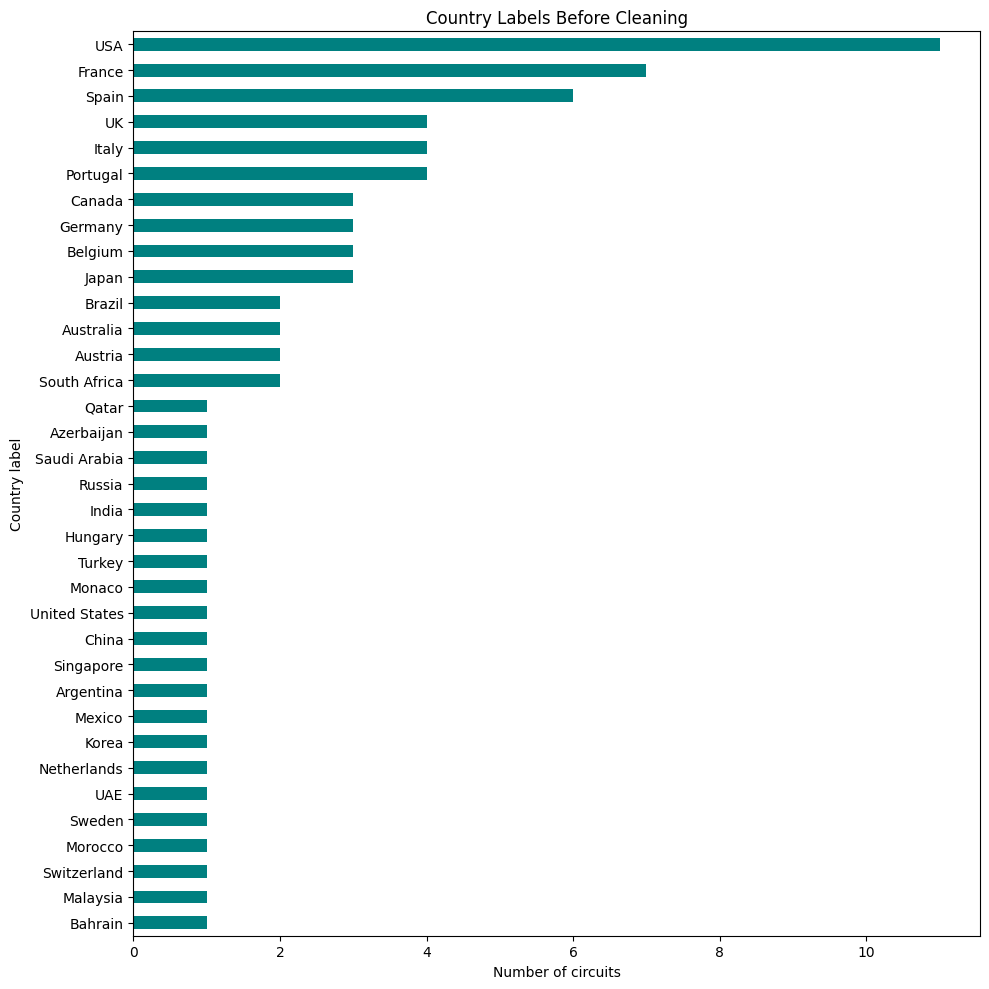

In [14]:
import matplotlib.pyplot as plt

counts = circuits["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [16]:
# Create a cleaned copy; preserve the original circuits table.
circuits_clean = circuits.copy(deep=True)
# Standardize the country name.
circuits_clean["country"] = circuits_clean["country"].replace({
    "USA": "United States"
})

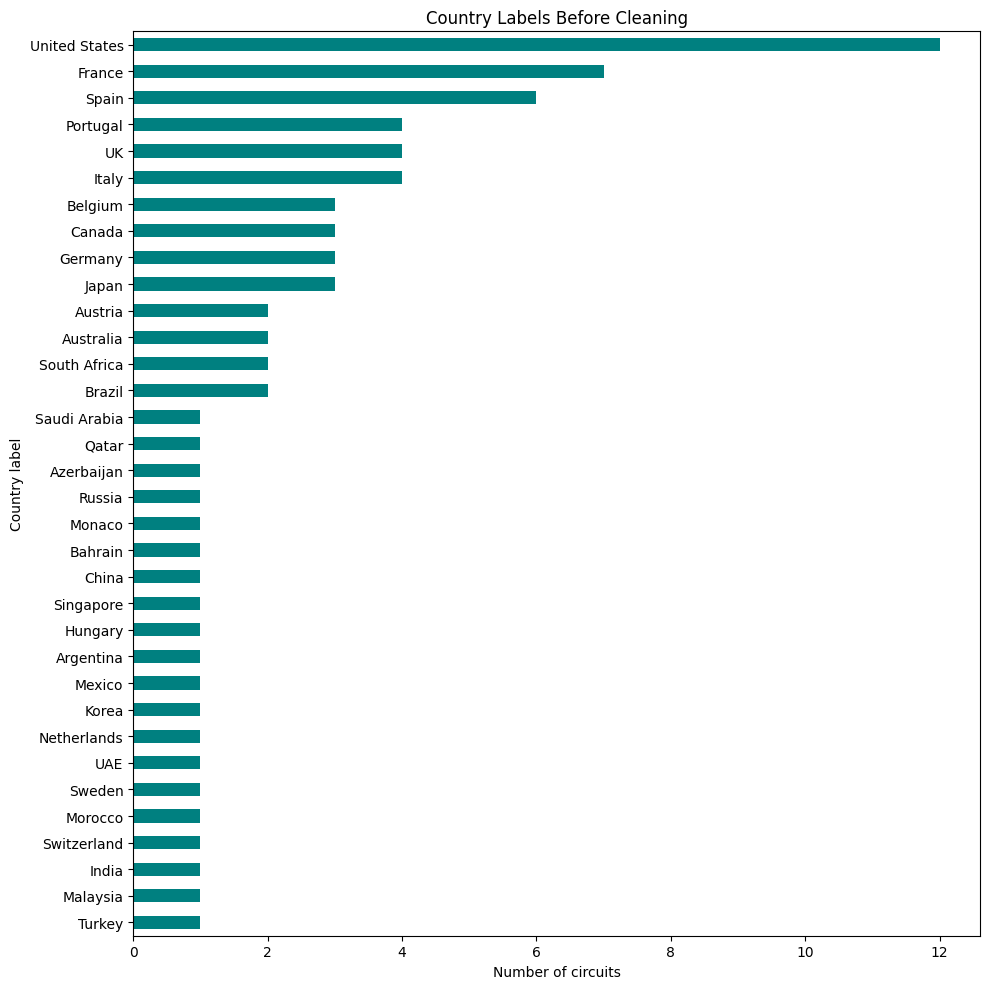

In [17]:
import matplotlib.pyplot as plt

counts = circuits_clean["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [34]:
print("Missing circuit IDs:",
      circuits_clean["circuitId"].isna().sum())

print("Duplicate circuit IDs:",
      circuits_clean["circuitId"].duplicated().sum())

assert circuits_clean["circuitId"].notna().all(), "Missing circuit IDs found"
assert circuits_clean["circuitId"].is_unique, "Duplicate circuit IDs found"

print("Passed: circuitId is unique and non-null.")

Missing circuit IDs: 0
Duplicate circuit IDs: 0
Passed: circuitId is unique and non-null.


constructor_results.csv

In [30]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


In [41]:
constructor_results_clean  =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv",na_values=[r"\N"]) 
constructor_results_clean.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [42]:
constructor_results_clean.isnull().sum()

constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64

In [32]:


display(
    constructor_results_clean["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Number of rows")
)

# Display the special flagged records.
display(
    constructor_results_clean.loc[
        constructor_results_clean["status"].notna()
    ]
)

,Status,Number of rows
0,NaN,12608
1,D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [46]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [47]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


Rezk

Mohamed 

Kareem

Hamza

**seasons.csv**

In [10]:
seasons_clean = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv",na_values=[r"\N"]) 

In [13]:
seasons_clean.head()

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [14]:
seasons_clean.isnull().sum()

year    0
url     0
dtype: int64

**sprint_results.csv**

In [23]:
sprint_results_clean =  pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv",na_values=[r"\N"])


In [26]:
sprint_results.isnull().sum()

resultId          0
raceId            0
driverId          0
constructorId     0
number            0
grid              0
position          0
positionText      0
positionOrder     0
points            0
laps              0
time              0
milliseconds      0
fastestLap        0
fastestLapTime    0
statusId          0
dtype: int64

In [25]:
sprint_results_clean.isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64

In [49]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ KB


In [47]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


In [46]:
sprint_results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,1538.426,1538426.0,14.0,90.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,1.43,1539856.0,17.0,89.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,7.502,1545928.0,17.0,89.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,11.278,1549704.0,16.0,90.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,24.111,1562537.0,16.0,90.566,1


In [42]:
def time_to_seconds(x):
    if pd.isna(x):
        return pd.NA

    x = str(x)

    # Remove leading +
    if x.startswith("+"):
        x = x[1:]

    # mm:ss.xxx
    if ":" in x:
        minutes, seconds = x.split(":")
        return int(minutes) * 60 + float(seconds)

    # seconds.xxx
    return float(x)

In [50]:
sprint_results_clean["time"] = sprint_results_clean["time"].apply(time_to_seconds)

In [51]:
sprint_results_clean["fastestLapTime"] = sprint_results_clean["fastestLapTime"].apply(time_to_seconds)

In [54]:
sprint_results_clean["time"] = pd.to_numeric(
    sprint_results_clean["time"].apply(time_to_seconds),
    errors="coerce"
)

sprint_results_clean["fastestLapTime"] = pd.to_numeric(
    sprint_results_clean["fastestLapTime"].apply(time_to_seconds),
    errors="coerce"
)

In [56]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    float64
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    float64
 15  statusId        360 non-null    int64  
dtypes: float64(5), int64(10), object(1)
memory usage: 45.1+ KB


In [65]:
sprint_results_clean.duplicated(
    subset=["raceId", "driverId"]
).sum()

np.int64(0)

In [66]:
duplicates = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
]

duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId


**status.csv**

In [58]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [59]:
status_clean = pd.read_csv("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv",na_values=[r"\N"]) 

In [61]:
status.isnull().sum()

statusId    0
status      0
dtype: int64

In [ ]:
status.duplicated(subset=["statusId"]).sum()

Testing uniqueness of the 3 tables